# Занятие 5. Замкнутые кинематические цепи: параллельные манипуляторы — демонстрации

Конспект: лекция 5 (разделы 5.1–5.11). Модуль `parallel.py` (расчётные функции и рисование скелетов), цвета и двухзвенник — из `kinlib.py`.
Все числа сверяются с примерами 5.1–5.7 конспекта.

| № | Демонстрация | Слайды | Конспект |
|---|---|---|---|
| 1 | Подвижность по структурной формуле; избыточные связи | 6–8 | § 5.2 |
| 2 | Пятизвенник: прямая задача пересечением окружностей, режимы сборки и рабочие режимы, $A\dot{\mathbf x}=B\dot{\mathbf q}$ | 11–13 | § 5.3, пример 5.1 |
| 3 | Параллелограммный манипулятор: прямая и обратная задачи, горизонтальный фланец | 14–15 | § 5.4, пример 5.2 |
| 4 | Рабочая зона параллелограммного манипулятора | 16 | § 5.4 |
| 5 | Дельта-робот: обратная задача, таблица $E_i, F_i, G_i$, скелет | 25–27 | § 5.6, пример 5.3 |
| 6 | Дельта-робот: прямая задача тремя сферами, круговая проверка; линейный вариант | 28–29, 32 | § 5.7–5.8, примеры 5.4, 5.5 |
| 7 | Рабочая зона дельта-робота: сечения и облако точек | 34 | § 5.9 |
| 8 | Матрица Якоби дельта-робота и близость к особенностям | 33, 38 | § 5.9, 5.11, пример 5.6 |
| 9 | Платформа Гью — Стюарта: длины ног, метод Ньютона, режимы сборки | 35–37 | § 5.10, пример 5.7 |
| 10 | Интерактив: дельта-робот с ползунками | — | — |

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath('.'))
import numpy as np
import matplotlib.pyplot as plt
from kinlib import NAVY, AMB, TEAL, RED, GREY, ICE, GREEN, ik2r, fk2r
from parallel import *
np.set_printoptions(precision=4, suppress=True)
warnings.filterwarnings('ignore')
%matplotlib inline
deg, rad = np.degrees, np.radians

## 1. Число степеней подвижности по структурной формуле (§ 5.2)

$W=\lambda\,(N-1-j)+\sum f_i$, где $N$ — число звеньев со стойкой, $j$ — число сочленений, $f_i$ — их подвижности, $\lambda=3$ на плоскости и $6$ в пространстве.
Формула не знает о размерах звеньев, поэтому при избыточных связях ошибается: параллелограмм с третьим кривошипом даёт $W=0$, дельта-робот с полными параллелограммами — $W=-9$.

In [2]:
cases = [
    ('шарнирный четырёхзвенник',                    4,  4,  4, 3, 1),
    ('плоский пятизвенник 5R',                      5,  5,  5, 3, 2),
    ('параллелограмм с третьим кривошипом',         5,  6,  6, 3, 1),
    ('дельта-робот 3-RUU (эквивалентная схема)',    8,  9, 3*1 + 6*2, 6, 3),
    ('дельта-робот, все параллелограммы (21 R)',   17, 21, 21, 6, 3),
    ('дельта-робот, по одной штанге убрано',       14, 15, 15, 6, 3),
    ('платформа 6-UPS',                            14, 18, 6*(2 + 1 + 3), 6, 6),
    ('платформа 6-SPS (местные подвижности)',      14, 18, 6*(3 + 1 + 3), 6, 6),
]
print('%-46s %3s %3s %5s %4s %6s' % ('механизм', 'N', 'j', 'sum f', 'W', 'факт'))
for name, N, j, fs, lam, fact in cases:
    W = mobility(N, j, fs, lam)
    print('%-46s %3d %3d %5d %4d %6d %s' % (name, N, j, fs, W, fact, '' if W == fact else '  <- формула ошибается'))

механизм                                         N   j sum f    W   факт
шарнирный четырёхзвенник                         4   4     4    1      1 
плоский пятизвенник 5R                           5   5     5    2      2 
параллелограмм с третьим кривошипом              5   6     6    0      1   <- формула ошибается
дельта-робот 3-RUU (эквивалентная схема)         8   9    15    3      3 
дельта-робот, все параллелограммы (21 R)        17  21    21   -9      3   <- формула ошибается
дельта-робот, по одной штанге убрано            14  15    15    3      3 
платформа 6-UPS                                 14  18    36    6      6 
платформа 6-SPS (местные подвижности)           14  18    42   12      6   <- формула ошибается


## 2. Плоский пятизвенник: прямая задача — пересечение двух окружностей (§ 5.3, пример 5.1)

$d=0{,}3$, $l_1=0{,}3$, $l_2=0{,}45$ м, $q=(100^\circ;\,30^\circ)$. Точка $P$ лежит на пересечении окружностей радиуса $l_2$ с центрами $B_1$, $B_2$: два **режима сборки** $P^{\pm}$. Обратная задача — два независимых двухзвенника, четыре **рабочих режима**.
Ожидаем $P^{+}=(0{,}1783;\ 0{,}5359)$, $P^{-}=(0{,}0294;\ -0{,}0904)$, $\kappa(J)=1{,}08$.

B1 = [-0.2021  0.2954]  B2 = [0.4098 0.15  ]  D = 0.6289
P+ = [0.1783 0.5359] 
P- = [ 0.0294 -0.0904]
A =
 [[ 0.3804  0.2404]
 [-0.2315  0.3859]] 
B =
 [[-0.1249  0.    ]
 [ 0.      0.135 ]] 
J = A^-1 B =
 [[-0.2381 -0.1603]
 [-0.1428  0.2536]] 
число обусловленности J = 1.084

ОЗК для точки P+: четыре рабочих режима (градусы)
  излом (+1, +1): q = [100.    143.956]
  излом (+1, -1): q = [100.  30.]
  излом (-1, +1): q = [ 17.015 143.956]
  излом (-1, -1): q = [17.015 30.   ]


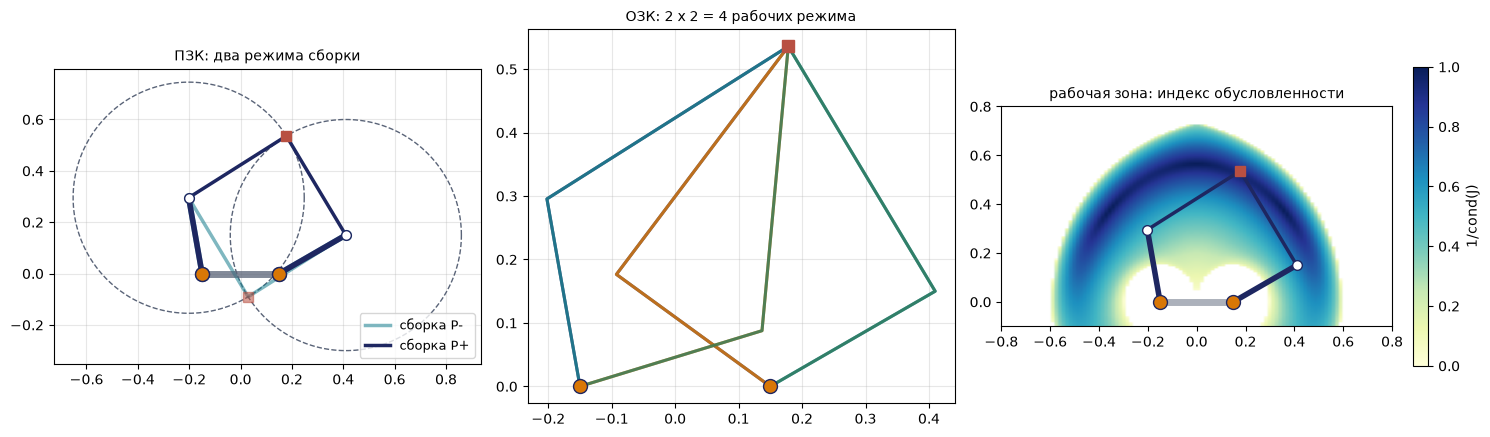

In [3]:
q = rad([100.0, 30.0])
Pp, B1, B2 = fivebar_fk(q[0], q[1], +1); Pm, _, _ = fivebar_fk(q[0], q[1], -1)
print('B1 =', B1, ' B2 =', B2, ' D = %.4f' % np.linalg.norm(B2 - B1))
print('P+ =', Pp, '\nP- =', Pm)
A, B, J = fivebar_jac(Pp, q)
print('A =\n', A, '\nB =\n', B, '\nJ = A^-1 B =\n', J, '\nчисло обусловленности J = %.3f' % np.linalg.cond(J))

fig, axs = plt.subplots(1, 3, figsize=(15, 4.8))
ax = axs[0]; tt = np.linspace(0, 2*np.pi, 200)
for Bc in (B1, B2):
    ax.plot(Bc[0] + FB_L2*np.cos(tt), Bc[1] + FB_L2*np.sin(tt), color=GREY, lw=1, ls='--')
draw_fivebar(ax, q[0], q[1], -1, color=TEAL, alpha=0.55, label='сборка P-')
draw_fivebar(ax, q[0], q[1], +1, color=NAVY, label='сборка P+')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=9, loc='lower right'); ax.set_title('ПЗК: два режима сборки', fontsize=10)

ax = axs[1]; cols = (NAVY, TEAL, AMB, GREEN); k = 0
print('\nОЗК для точки P+: четыре рабочих режима (градусы)')
for s1 in (+1, -1):
    for s2 in (+1, -1):
        qq = fivebar_ik(Pp, s1, s2); print('  излом (%+d, %+d): q =' % (s1, s2), deg(qq).round(3))
        for xa, qi in ((-FB_D/2, qq[0]), (FB_D/2, qq[1])):
            Bk = np.array([xa + FB_L1*np.cos(qi), FB_L1*np.sin(qi)])
            ax.plot([xa, Bk[0], Pp[0]], [0, Bk[1], Pp[1]], color=cols[k], lw=2.2, alpha=0.8)
        k += 1
ax.plot([Pp[0]], [Pp[1]], 's', color=RED, ms=8, zorder=6); ax.plot([-FB_D/2, FB_D/2], [0, 0], 'o', color=AMB, mec=NAVY, ms=10)
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_title('ОЗК: 2 x 2 = 4 рабочих режима', fontsize=10)

xs, ys, M = fivebar_workspace(n=110)
ax = axs[2]; im = ax.imshow(M, extent=[xs[0], xs[-1], ys[0], ys[-1]], origin='lower', cmap='YlGnBu', vmin=0, vmax=1)
draw_fivebar(ax, q[0], q[1], +1); plt.colorbar(im, ax=ax, fraction=0.035, label='1/cond(J)')
ax.set_title('рабочая зона: индекс обусловленности', fontsize=10)
plt.tight_layout(); plt.show()

## 3. Параллелограммный манипулятор: прямая и обратная задачи (§ 5.4, пример 5.2)

$h=0{,}8$, $l_2=1{,}0$, $l_3=1{,}2$, $d=0{,}2$, $e=0{,}25$ м. Привод кривошипа задаёт **абсолютный** угол предплечья $q_3=q_2+\vartheta_3$.
Ожидаем: $q=(30^\circ;60^\circ;-20^\circ)\ \to\ P=(1{,}5828;\ 0{,}9138;\ 1{,}0056)$; $P=(1{,}5;0{,}8;0{,}9)\ \to\ q=(28{,}07^\circ;\ 64{,}28^\circ;\ -27{,}33^\circ)$.
Сравниваем с обычным двухзвенником из `kinlib` и рисуем движение по вертикали: фланец остаётся горизонтальным.

ПЗК: q = (30, 60, -20) град ->  P = [1.5828 0.9138 1.0056] ;  вылет r = 1.8276 м
ОЗК обратно (град): [ 30.  60. -20.]
угол в локте theta3 = q3 - q2 = -80.0 град;  det J_rz = l2 l3 sin(q3 - q2) = -1.1818 = -1.1818
ОЗК: P = (1.5, 0.8, 0.9) -> q (град) = [ 28.072  64.282 -27.33 ] ;  ПЗК обратно: [1.5 0.8 0.9]
kinlib.ik2r: q2 = 64.282, theta3 = -91.612  ->  q3 = q2 + theta3 = -27.330 град


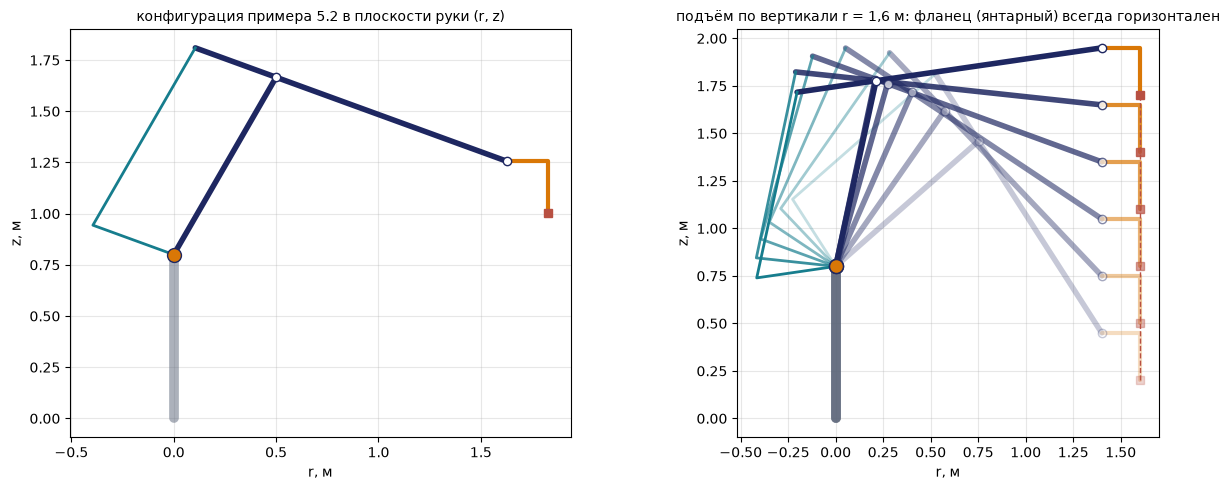

In [4]:
q = rad([30.0, 60.0, -20.0]); P = pgram_fk(q)
print('ПЗК: q = (30, 60, -20) град ->  P =', P, ';  вылет r = %.4f м' % np.hypot(P[0], P[1]))
print('ОЗК обратно (град):', deg(pgram_ik(P)).round(6))
print('угол в локте theta3 = q3 - q2 = %.1f град;  det J_rz = l2 l3 sin(q3 - q2) = %.4f = %.4f' % (deg(q[2] - q[1]), PG_L2*PG_L3*np.sin(q[2] - q[1]), np.linalg.det(pgram_jac_rz(q))))
q_b = pgram_ik([1.5, 0.8, 0.9]); print('ОЗК: P = (1.5, 0.8, 0.9) -> q (град) =', deg(q_b).round(3), ';  ПЗК обратно:', pgram_fk(q_b).round(6))
# тот же ответ через двухзвенник kinlib: углы звеньев (q2, theta3) -> углы приводов (q2, q2 + theta3)
rr, zz = np.hypot(1.5, 0.8) - PG_D, 0.9 - PG_H + PG_E
sol = [s for s in ik2r(rr, zz, (PG_L2, PG_L3)) if s[1] < 0][0]
print('kinlib.ik2r: q2 = %.3f, theta3 = %.3f  ->  q3 = q2 + theta3 = %.3f град' % (deg(sol[0]), deg(sol[1]), deg(sol[0] + sol[1])))

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
ax = axs[0]; draw_pgram(ax, q); ax.set_aspect('equal'); ax.grid(alpha=.3)
ax.set_title('конфигурация примера 5.2 в плоскости руки (r, z)', fontsize=10); ax.set_xlabel('r, м'); ax.set_ylabel('z, м')
ax = axs[1]; zs_line = np.linspace(0.2, 1.7, 6)
for k, z in enumerate(zs_line):
    qk = pgram_ik([1.6, 0.0, z]); draw_pgram(ax, qk, alpha=0.25 + 0.75*k/(len(zs_line) - 1))
ax.plot([1.6, 1.6], [zs_line[0], zs_line[-1]], color=RED, lw=1, ls='--')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_xlabel('r, м'); ax.set_ylabel('z, м')
ax.set_title('подъём по вертикали r = 1,6 м: фланец (янтарный) всегда горизонтален', fontsize=10)
plt.tight_layout(); plt.show()

## 4. Рабочая зона параллелограммного манипулятора (§ 5.4)

Перебираем точки плоскости $(r,z)$, решаем обратную задачу и проверяем ограничения: $20^\circ\le q_2\le130^\circ$, $-75^\circ\le q_3\le35^\circ$, угол между плечом и предплечьем $25^\circ\le q_2-q_3\le155^\circ$ (иначе параллелограмм вырождается). Цвет — $\lvert\sin(q_2-q_3)\rvert$, пропорциональный $\det J_{rz}$.

площадь сечения зоны: 3.08 м^2;  доля зоны с |sin(q2 - q3)| > 0,8: 75 %
вылет r: от 0.56 до 2.33 м;  высота z: от -0.26 до 2.22 м


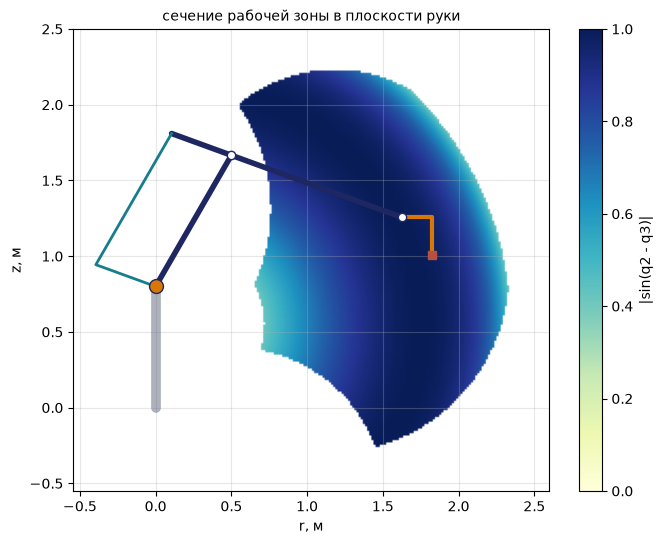

In [5]:
rs, zs, M = pgram_workspace(n=200)
cell = (rs[1] - rs[0]) * (zs[1] - zs[0])
print('площадь сечения зоны: %.2f м^2;  доля зоны с |sin(q2 - q3)| > 0,8: %.0f %%' % (np.isfinite(M).sum()*cell, 100*np.nansum(M > 0.8)/np.isfinite(M).sum()))
print('вылет r: от %.2f до %.2f м;  высота z: от %.2f до %.2f м' % (rs[np.isfinite(M).any(0)][0], rs[np.isfinite(M).any(0)][-1], zs[np.isfinite(M).any(1)][0], zs[np.isfinite(M).any(1)][-1]))
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(M, extent=[rs[0], rs[-1], zs[0], zs[-1]], origin='lower', cmap='YlGnBu', vmin=0, vmax=1)
draw_pgram(ax, rad([30.0, 60.0, -20.0])); plt.colorbar(im, ax=ax, fraction=0.04, label='|sin(q2 - q3)|')
ax.set_xlabel('r, м'); ax.set_ylabel('z, м'); ax.set_title('сечение рабочей зоны в плоскости руки', fontsize=10); ax.grid(alpha=.3)
plt.show()

## 5. Дельта-робот: обратная задача о положении (§ 5.6, пример 5.3)

Размеры ABB FlexPicker IRB 360 по Р. Уильямсу: $s_B=0{,}567$, $s_P=0{,}076$, $L=0{,}524$, $l=1{,}244$ м, $a=w_B-u_P=0{,}1198$ м. Для каждой ноги $E_i\cos\theta_i+F_i\sin\theta_i+G_i=0$, $t=\operatorname{tg}(\theta/2)$; рабочая ветвь «колени наружу» — знак минус перед корнем.
Ожидаем: $(0;0;-0{,}9)\to\theta=-20{,}547^\circ$; $(0{,}3;0{,}5;-1{,}1)\to(47{,}504^\circ;\ -11{,}569^\circ;\ 21{,}378^\circ)$.

wB = 0.1637, uP = 0.0439, a = 0.1198 м

p = [0.0, 0.0, -0.9] 
  колени наружу: theta = [-20.547 -20.547 -20.547] град
  колени внутрь:  theta = [-144.29 -144.29 -144.29] град
  нога |    xi    |   eta    |    E     |    F     |    G     |    t     | theta, град
   1   |  -0.1198 |   0.0000 |   0.1256 |  -0.9432 |  -0.4486 |  -0.1813 |  -20.547
   2   |  -0.1198 |   0.0000 |   0.1256 |  -0.9432 |  -0.4486 |  -0.1813 |  -20.547
   3   |  -0.1198 |   0.0000 |   0.1256 |  -0.9432 |  -0.4486 |  -0.1813 |  -20.547

p = [0.3, 0.5, -1.1] 
  колени наружу: theta = [ 47.504 -11.569  21.378] град
  колени внутрь:  theta = [-168.71  152.52  172.06] град
  нога |    xi    |   eta    |    E     |    F     |    G     |    t     | theta, град
   1   |  -0.6198 |   0.3000 |   0.6496 |  -1.1528 |   0.4112 |   0.4401 |   47.504
   2   |   0.3900 |   0.2830 |  -0.4087 |  -1.1528 |   0.1692 |  -0.1013 |  -11.569
   3   |  -0.1296 |  -0.5830 |   0.1358 |  -1.1528 |   0.2937 |   0.1888 |   21.378

недостижим

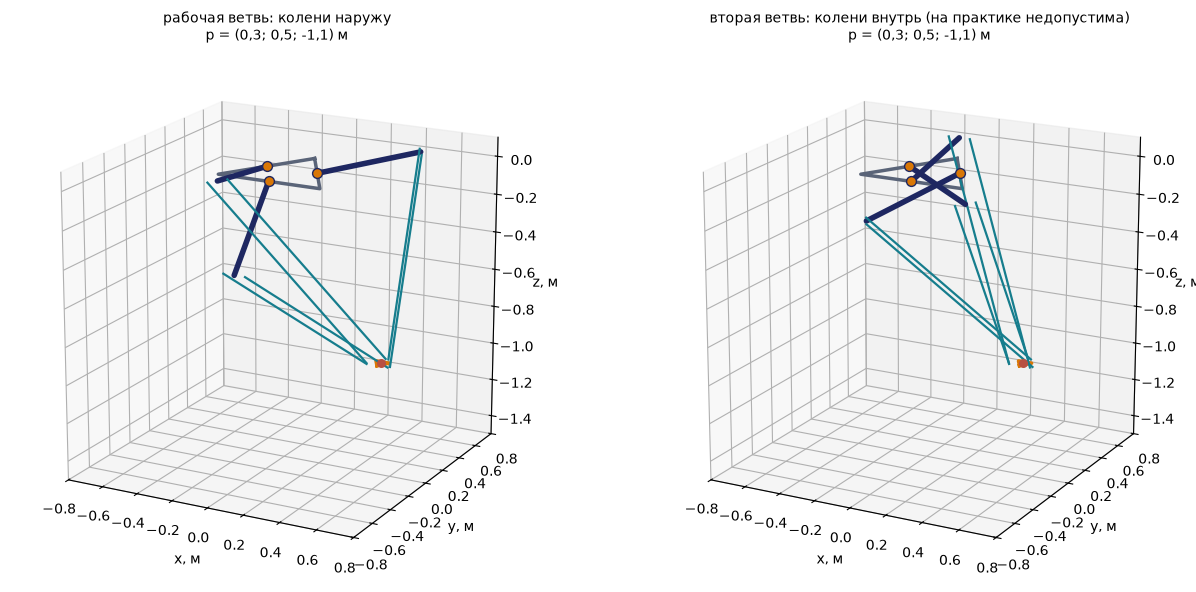

In [6]:
print('wB = %.4f, uP = %.4f, a = %.4f м' % (WB, UP, WB - UP))
for p in ([0.0, 0.0, -0.9], [0.3, 0.5, -1.1]):
    th = delta_ik(p); th_in = delta_ik(p, branch=+1)
    print('\np =', p, '\n  колени наружу: theta =', deg(th).round(3), 'град\n  колени внутрь:  theta =', deg(th_in).round(2), 'град')
    print('  нога |    xi    |   eta    |    E     |    F     |    G     |    t     | theta, град')
    for i, r in enumerate(delta_ik_table(p)):
        print('   %d   | %8.4f | %8.4f | %8.4f | %8.4f | %8.4f | %8.4f | %8.3f' % ((i + 1,) + tuple(r[:6]) + (deg(r[6]),)))
print('\nнедостижимая точка (0.9, 0.9, -1.0):', delta_ik([0.9, 0.9, -1.0]))

fig = plt.figure(figsize=(13, 6))
for k, (p, br, ttl) in enumerate((([0.3, 0.5, -1.1], -1, 'рабочая ветвь: колени наружу'), ([0.3, 0.5, -1.1], +1, 'вторая ветвь: колени внутрь (на практике недопустима)'))):
    ax = fig.add_subplot(1, 2, k + 1, projection='3d'); draw_delta(ax, p, delta_ik(p, branch=br)); ax.view_init(18, -62)
    ax.set_title('%s\np = (0,3; 0,5; -1,1) м' % ttl, fontsize=10)
plt.tight_layout(); plt.show()

## 6. Дельта-робот: прямая задача — пересечение трёх сфер (§ 5.7–5.8, примеры 5.4 и 5.5)

Платформа не поворачивается, поэтому центры сфер можно сдвинуть на $-\mathbf P_i$: $\mathbf A_i^{v}=(a+L\cos\theta_i)\mathbf u_i-L\sin\theta_i\mathbf k$, и центр платформы — точка пересечения трёх сфер радиуса $l$.
Ожидаем: $\theta=(10^\circ;20^\circ;30^\circ)\to\mathbf p=(0{,}1081;\ -0{,}1803;\ -1{,}2435)$; круговая проверка ОЗК → ПЗК с ошибкой менее $10^{-9}$.

виртуальный центр A1^v = [ 0.     -0.6358 -0.091 ]
виртуальный центр A2^v = [ 0.5302  0.3061 -0.1792]
виртуальный центр A3^v = [-0.4968  0.2868 -0.262 ]
два решения: [-0.0699  0.1201  0.8945] и [ 0.1081 -0.1803 -1.2435]
ПЗК: theta = (10, 20, 30) град ->  p = [ 0.1081 -0.1803 -1.2435] ;  ОЗК обратно: [10. 20. 30.]
ПЗК: theta = (0, 0, 0) -> p = [ 0.     -0.     -1.0645]  (равные высоты коленей — особенности у алгоритма нет)
круговая проверка на 2000 случайных точках: max |ПЗК(ОЗК(p)) - p| = 3.28e-13 м  (< 1e-9: True)


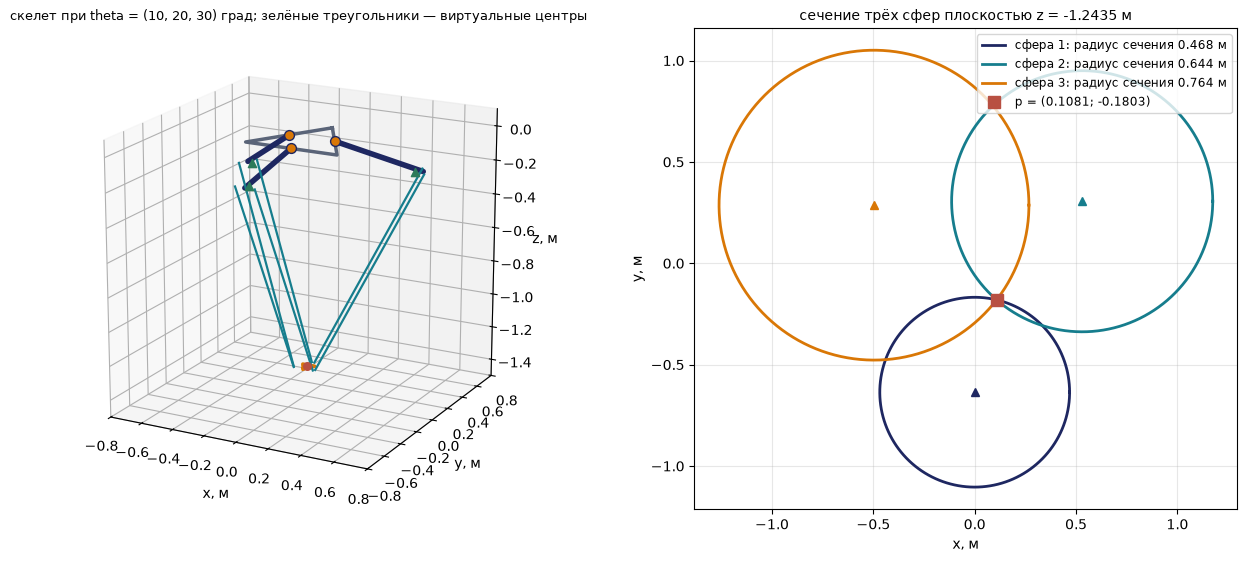

In [7]:
th = rad([10.0, 20.0, 30.0]); a = WB - UP
cs = [(a + LU*np.cos(th[i]))*uvec(i) - LU*np.sin(th[i])*KZ for i in range(3)]
for i, c in enumerate(cs): print('виртуальный центр A%d^v =' % (i + 1), c.round(4))
s1, s2 = trilaterate(cs[0], cs[1], cs[2], LL, LL, LL)
print('два решения:', s1.round(4), 'и', s2.round(4))
p = delta_fk(th); print('ПЗК: theta = (10, 20, 30) град ->  p =', p.round(4), ';  ОЗК обратно:', deg(delta_ik(p)).round(9))
print('ПЗК: theta = (0, 0, 0) -> p =', delta_fk(np.zeros(3)).round(4), ' (равные высоты коленей — особенности у алгоритма нет)')

rng = np.random.RandomState(1); worst = 0.0; cnt = 0
for k in range(2000):
    pr = np.array([rng.uniform(-0.4, 0.4), rng.uniform(-0.4, 0.4), rng.uniform(-1.3, -0.8)]); t_ = delta_ik(pr)
    if t_ is None: continue
    worst = max(worst, np.linalg.norm(delta_fk(t_) - pr)); cnt += 1
print('круговая проверка на %d случайных точках: max |ПЗК(ОЗК(p)) - p| = %.2e м  (< 1e-9: %s)' % (cnt, worst, worst < 1e-9))

fig = plt.figure(figsize=(13, 5.6))
ax = fig.add_subplot(1, 2, 1, projection='3d'); draw_delta(ax, p, th); ax.view_init(18, -62)
for c in cs: ax.scatter(*c, color=GREEN, s=35, marker='^', depthshade=False)
ax.set_title('скелет при theta = (10, 20, 30) град; зелёные треугольники — виртуальные центры', fontsize=9.5)
ax = fig.add_subplot(1, 2, 2); tt = np.linspace(0, 2*np.pi, 300)
for i, (c, col) in enumerate(zip(cs, (NAVY, TEAL, AMB))):
    rho = np.sqrt(LL**2 - (p[2] - c[2])**2)
    ax.plot(c[0] + rho*np.cos(tt), c[1] + rho*np.sin(tt), color=col, lw=2, label='сфера %d: радиус сечения %.3f м' % (i + 1, rho)); ax.plot(c[0], c[1], '^', color=col)
ax.plot(p[0], p[1], 's', color=RED, ms=9, zorder=6, label='p = (%.4f; %.4f)' % (p[0], p[1]))
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=8.5, loc='upper right'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
ax.set_title('сечение трёх сфер плоскостью z = %.4f м' % p[2], fontsize=10)
plt.tight_layout(); plt.show()

**Линейный дельта-робот 3-PUU (пример 5.5).** Обратная задача — одна строка без тригонометрии: $d_i=-z-\sqrt{l^2-\rho_i^2}$; прямая — те же три сферы с центрами $a\mathbf u_i-d_i\mathbf k$.
Ожидаем: $(0;0;-0{,}5)\to d=0{,}2451$; $(0{,}03;0{,}05;-0{,}40)\to(0{,}1664;0{,}1516;0{,}1384)$; $d=(0{,}14;0{,}15;0{,}16)\to(-0{,}0215;-0{,}0363;-0{,}4012)$.

R_B = 0.1420, u_P = 0.0733, a = 0.0687, l = 0.264 м
ОЗК: p = [0.0, 0.0, -0.5] -> d = [0.2451 0.2451 0.2451] ;  ошибка ПЗК(ОЗК) = 3.1e-33
ОЗК: p = [0.03, 0.05, -0.4] -> d = [0.1664 0.1516 0.1384] ;  ошибка ПЗК(ОЗК) = 7.1e-17
ПЗК: d = [0.2, 0.2, 0.2] -> p = [ 0.      0.     -0.4549]
ПЗК: d = [0.14, 0.15, 0.16] -> p = [-0.0215 -0.0363 -0.4012]


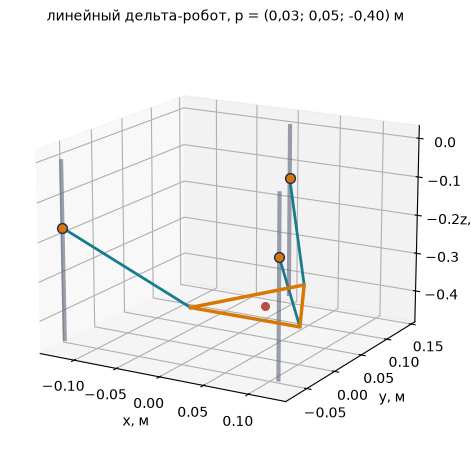

In [8]:
print('R_B = %.4f, u_P = %.4f, a = %.4f, l = %.3f м' % (LIN_RB, LIN_UP, LIN_RB - LIN_UP, LIN_L))
for p_ in ([0.0, 0.0, -0.5], [0.03, 0.05, -0.40]):
    d_ = lindelta_ik(p_); print('ОЗК: p =', p_, '-> d =', d_.round(4), ';  ошибка ПЗК(ОЗК) = %.1e' % np.linalg.norm(lindelta_fk(d_) - p_))
for d_ in ([0.2, 0.2, 0.2], [0.14, 0.15, 0.16]):
    print('ПЗК: d =', d_, '-> p =', lindelta_fk(np.array(d_)).round(4))
fig = plt.figure(figsize=(5.6, 5.6)); ax = fig.add_subplot(111, projection='3d'); draw_lindelta(ax, [0.03, 0.05, -0.40]); ax.view_init(16, -60)
ax.set_title('линейный дельта-робот, p = (0,03; 0,05; -0,40) м', fontsize=10); plt.show()

## 7. Рабочая зона дельта-робота (§ 5.9)

Строим зону через обратную задачу: точка принадлежит зоне, если ОЗК решается, $-45^\circ\le\theta_i\le95^\circ$ и штанги отклонены от плоскости ноги не более чем на $40^\circ$. Цвет — локальный индекс обусловленности $1/\kappa(J)$. Серые точки — облако, полученное вторым способом: перебором углов приводов и прямой задачей.
По конспекту: на оси робота зона от $z=-0{,}78$ до $-1{,}76$ м, вдоль $x$ до $\pm0{,}80$ м, максимум индекса около $0{,}43$.

на оси робота зона от z = -0.77 до z = -1.76 м
на высоте z = -1,0 м: вдоль x до 0.80 м, вдоль y до 0.92 м
максимум 1/cond(J) в сечении y = 0: 0.427 в точке x = 0.01, z = -1.06 м
облако ПЗК: 1607 точек из 2500 удовлетворяют ограничениям


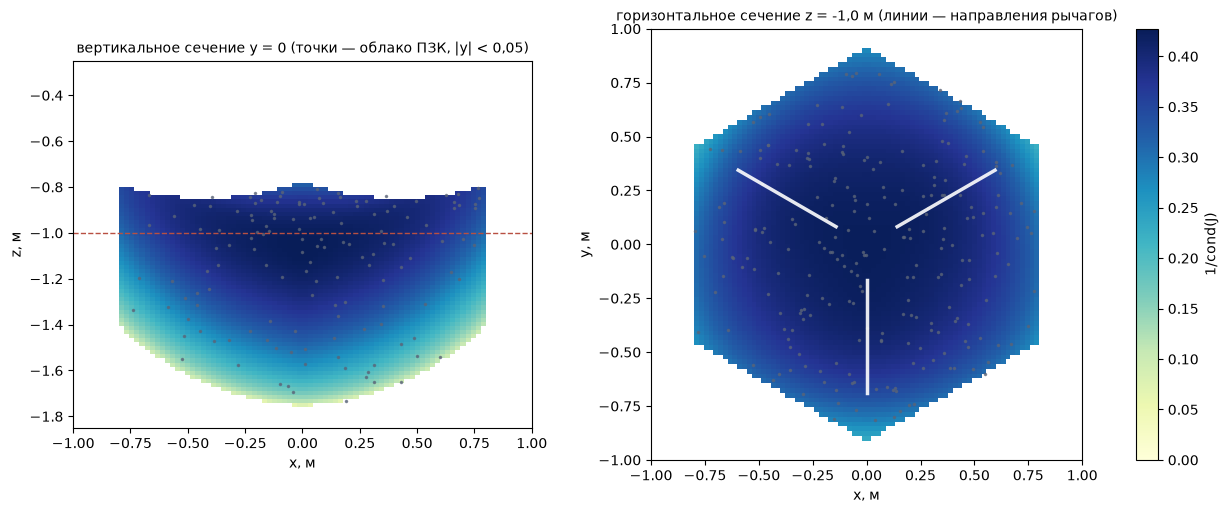

In [9]:
xs, zs, M1 = delta_section('xz', 0.0, n=90)
xs2, ys2, M2 = delta_section('xy', -1.0, n=90)
cloud = delta_cloud(2500)
zax = np.linspace(-1.9, -0.6, 651); ok = np.array([np.isfinite(delta_quality([0, 0, z])) for z in zax])
xax = np.linspace(0, 1.0, 501); okx = np.array([np.isfinite(delta_quality([x, 0, -1.0])) for x in xax])
yax = np.linspace(0, 1.1, 551); oky = np.array([np.isfinite(delta_quality([0, y, -1.0])) for y in yax])
print('на оси робота зона от z = %.2f до z = %.2f м' % (zax[ok][-1], zax[ok][0]))
print('на высоте z = -1,0 м: вдоль x до %.2f м, вдоль y до %.2f м' % (xax[okx][-1], yax[oky][-1]))
iz, ix = np.unravel_index(np.nanargmax(M1), M1.shape); print('максимум 1/cond(J) в сечении y = 0: %.3f в точке x = %.2f, z = %.2f м' % (np.nanmax(M1), xs[ix], zs[iz]))
print('облако ПЗК: %d точек из 2500 удовлетворяют ограничениям' % len(cloud))
vmax = np.nanmax([np.nanmax(M1), np.nanmax(M2)])
fig, axs = plt.subplots(1, 2, figsize=(14, 5.6))
ax = axs[0]; im = ax.imshow(M1, extent=[xs[0], xs[-1], zs[0], zs[-1]], origin='lower', cmap='YlGnBu', vmin=0, vmax=vmax)
sl = np.abs(cloud[:, 1]) < 0.05; ax.plot(cloud[sl, 0], cloud[sl, 2], '.', color=GREY, ms=3, alpha=0.7)
ax.axhline(-1.0, color=RED, lw=1, ls='--'); ax.set_xlabel('x, м'); ax.set_ylabel('z, м'); ax.set_title('вертикальное сечение y = 0 (точки — облако ПЗК, |y| < 0,05)', fontsize=10)
ax = axs[1]; im = ax.imshow(M2, extent=[xs2[0], xs2[-1], ys2[0], ys2[-1]], origin='lower', cmap='YlGnBu', vmin=0, vmax=vmax)
sl = np.abs(cloud[:, 2] + 1.0) < 0.05; ax.plot(cloud[sl, 0], cloud[sl, 1], '.', color=GREY, ms=3, alpha=0.7)
for i in range(3):
    u = uvec(i); ax.plot([WB*u[0], (WB + LU)*u[0]], [WB*u[1], (WB + LU)*u[1]], color='white', lw=2.5, alpha=0.9)
ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.set_title('горизонтальное сечение z = -1,0 м (линии — направления рычагов)', fontsize=10)
fig.colorbar(im, ax=axs, fraction=0.02, label='1/cond(J)'); plt.show()

## 8. Матрица Якоби дельта-робота и близость к особенностям (§ 5.9, 5.11, пример 5.6)

$A\dot{\mathbf p}=B\dot{\boldsymbol\theta}$: строки $A$ — векторы штанг, $b_i=L\,\mathbf l_i^{\mathrm T}\mathbf w_i$, $J=A^{-1}B$.
Ожидаем в точке $(0;0;-0{,}9)$: $b_i=0{,}4196$, сингулярные числа $0{,}561;\ 0{,}561;\ 0{,}224$, $\kappa=2{,}511$; для $\dot x=0{,}5$ м/с — $\dot{\boldsymbol\theta}=(0;-0{,}63;0{,}63)$ рад/с.
Затем идём вниз по оси робота и смотрим, как $b_i\to0$ (особенность первого типа, граница зоны), а $\det A$ уменьшается (штанги сближаются по направлению), но в нуль не обращается: штанги не становятся компланарными.

A =
 [[-0.      0.6105 -1.0839]
 [-0.5287 -0.3052 -1.0839]
 [ 0.5287 -0.3052 -1.0839]] 
diag B = [0.4196 0.4196 0.4196] 
J = A^-1 B =
 [[-0.     -0.3968  0.3968]
 [ 0.4582 -0.2291 -0.2291]
 [-0.129  -0.129  -0.129 ]]
сингулярные числа: [0.5612 0.5612 0.2235] ;  число обусловленности = 2.511;  1/cond = 0.398
обратная задача о скорости, thdot = B^-1 A pdot:
   pdot = [0.5, 0, 0] м/с  ->  thdot = [-0.   -0.63  0.63] рад/с
   pdot = [0, 0, -0.5] м/с  ->  thdot = [1.292 1.292 1.292] рад/с
точка (0.3, 0.5, -1.1): J =
 [[-0.0427 -0.44    0.5708]
 [ 0.7489 -0.1872 -0.2949]
 [ 0.1228 -0.4404 -0.1625]] 
max |J - J_числ| = 1.9e-10;  cond J = 2.813


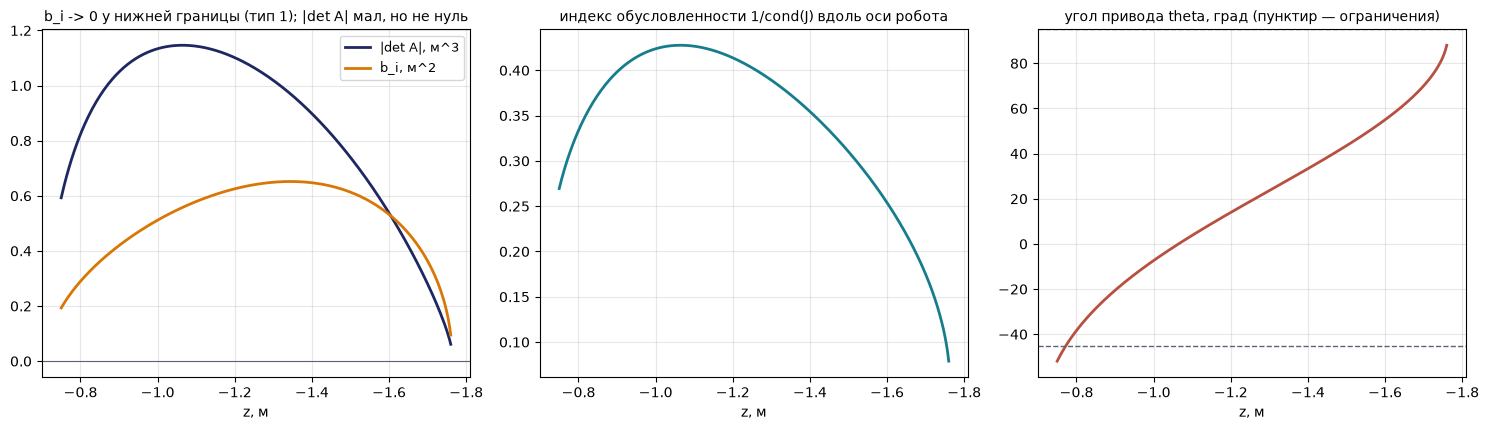

у нижней границы z = -1.760 м: b = 0.0948, theta = 88.0 град — рычаг и штанга вытягиваются в линию


In [10]:
p0 = np.array([0.0, 0.0, -0.9]); th0 = delta_ik(p0); A, B, J = delta_jac(p0, th0)
sv = np.linalg.svd(J, compute_uv=False)
print('A =\n', A, '\ndiag B =', np.diag(B), '\nJ = A^-1 B =\n', J)
print('сингулярные числа:', sv.round(4), ';  число обусловленности = %.3f;  1/cond = %.3f' % (sv[0]/sv[-1], sv[-1]/sv[0]))
print('обратная задача о скорости, thdot = B^-1 A pdot:')
for v in ([0.5, 0, 0], [0, 0, -0.5]):
    print('   pdot =', v, 'м/с  ->  thdot =', np.linalg.solve(B, A.dot(v)).round(3), 'рад/с')
p1 = np.array([0.3, 0.5, -1.1]); th1 = delta_ik(p1); A1, B1_, J1 = delta_jac(p1, th1); Jn = np.zeros((3, 3))
for j in range(3):
    dq = np.zeros(3); dq[j] = 1e-6; Jn[:, j] = (delta_fk(th1 + dq) - delta_fk(th1 - dq)) / 2e-6
print('точка (0.3, 0.5, -1.1): J =\n', J1, '\nmax |J - J_числ| = %.1e;  cond J = %.3f' % (np.abs(J1 - Jn).max(), np.linalg.cond(J1)))

zz = np.linspace(-0.75, -1.76, 300); detA, bb, ic, thz = [], [], [], []
for z in zz:
    t_ = delta_ik([0, 0, z]); A_, B_, J_ = delta_jac([0, 0, z], t_)
    detA.append(abs(np.linalg.det(A_))); bb.append(B_[0, 0]); ic.append(1/np.linalg.cond(J_)); thz.append(deg(t_[0]))
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
axs[0].plot(zz, detA, color=NAVY, lw=2, label='|det A|, м^3'); axs[0].plot(zz, bb, color=AMB, lw=2, label='b_i, м^2'); axs[0].axhline(0, color=GREY, lw=.8)
axs[0].set_title('b_i -> 0 у нижней границы (тип 1); |det A| мал, но не нуль', fontsize=10); axs[0].legend(fontsize=9)
axs[1].plot(zz, ic, color=TEAL, lw=2); axs[1].set_title('индекс обусловленности 1/cond(J) вдоль оси робота', fontsize=10)
axs[2].plot(zz, thz, color=RED, lw=2); axs[2].axhline(95, color=GREY, ls='--', lw=1); axs[2].axhline(-45, color=GREY, ls='--', lw=1)
axs[2].set_title('угол привода theta, град (пунктир — ограничения)', fontsize=10)
for ax in axs: ax.set_xlabel('z, м'); ax.grid(alpha=.3); ax.invert_xaxis()
plt.tight_layout(); plt.show()
print('у нижней границы z = %.3f м: b = %.4f, theta = %.1f град — рычаг и штанга вытягиваются в линию' % (zz[-1], bb[-1], thz[-1]))

## 9. Платформа Гью — Стюарта (§ 5.10, пример 5.7)

Обратная задача — одна строка: $l_i=\lVert\mathbf p+R\mathbf b_i-\mathbf a_i\rVert$. Прямая — метод Ньютона $\mathbf x_{k+1}=\mathbf x_k-J_l^{-1}[\mathbf l(\mathbf x_k)-\mathbf l^{\ast}]$.
Ожидаем: исходное положение — все ноги по $0{,}7954$ м; поза $(0{,}05;-0{,}03;0{,}75)$ с углами $5^\circ,-8^\circ,10^\circ$ → длины $(0{,}8124;\ 0{,}8916;\ 0{,}8796;\ 0{,}8531;\ 0{,}7638;\ 0{,}8710)$; Ньютон из исходного положения — 4 итерации.
Из далёких начальных приближений метод находит **другие режимы сборки** — иные позы с теми же длинами ног.

исходное положение: длины ног [0.7954 0.7954 0.7954 0.7954 0.7954 0.7954]
ОЗК: поза (0.05, -0.03, 0.75), углы (5, -8, 10) град -> длины [0.8124 0.8916 0.8796 0.8531 0.7638 0.871 ]
ПЗК, Ньютон из исходного положения: 4 итерации, ошибка позы 3.2e-16
обратная матрица Якоби (строки — оси ног): det = 0.1127, cond = 6.3
исходное положение          :  4 итераций, невязка 1.1e-16, p = [ 0.05 -0.03  0.75], углы = [ 5. -8. 10.] град
низкий старт z = 0,4 м      :  5 итераций, невязка 1.1e-16, p = [ 0.05 -0.03  0.75], углы = [ 5. -8. 10.] град
старт с разворотом 60 град  :  6 итераций, невязка 2.2e-16, p = [ 0.05 -0.03  0.75], углы = [ 5. -8. 10.] град
зеркальный старт z = -0,7 м :  4 итераций, невязка 1.1e-16, p = [ 0.05 -0.03 -0.75], углы = [-5.  8. 10.] град
далёкий наклонный старт     :  6 итераций, невязка 1.1e-16, p = [-0.3043 -0.1626  0.458 ], углы = [-111.9   25.2   -3.9] град


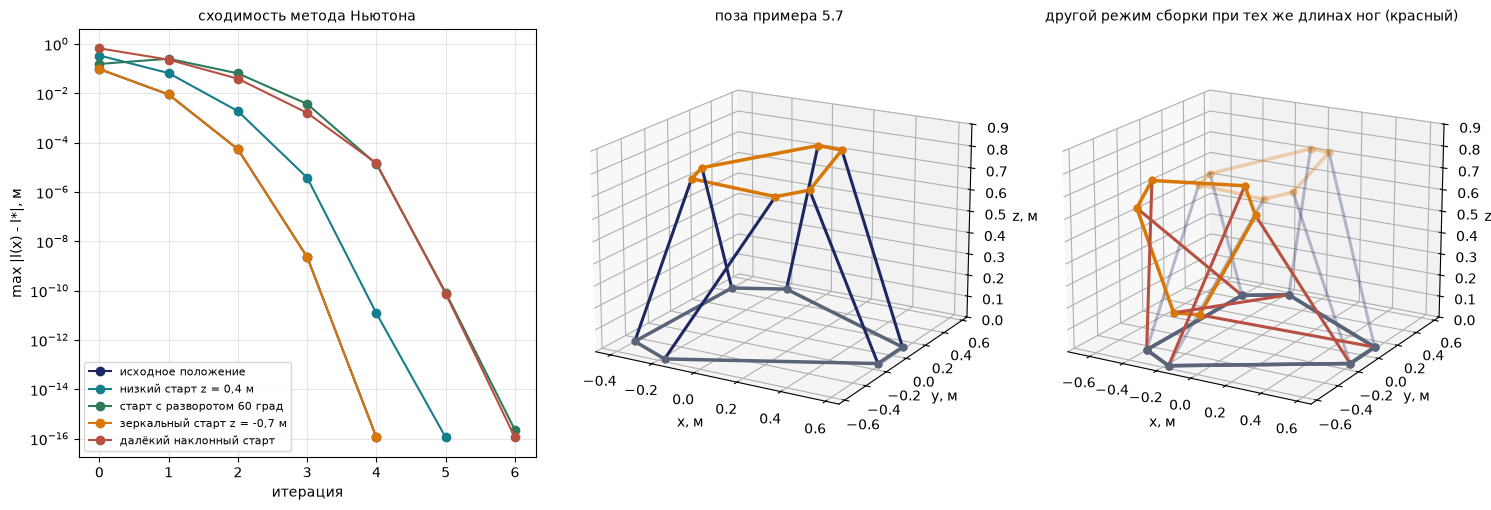

проверка: длины ног в найденном режиме сборки [0.8124 0.8916 0.8796 0.8531 0.7638 0.871 ]


In [11]:
x_home = np.array([0, 0, 0.70, 0, 0, 0.0]); print('исходное положение: длины ног', stewart_ik(x_home).round(4))
x_true = np.array([0.05, -0.03, 0.75, rad(5), rad(-8), rad(10)]); lens = stewart_ik(x_true)
print('ОЗК: поза (0.05, -0.03, 0.75), углы (5, -8, 10) град -> длины', lens.round(4))
xs_, it = stewart_fk(lens, x_home); print('ПЗК, Ньютон из исходного положения: %d итерации, ошибка позы %.1e' % (it, np.abs(xs_ - x_true).max()))
Jinv = stewart_invjac(x_true); print('обратная матрица Якоби (строки — оси ног): det = %.4f, cond = %.1f' % (np.linalg.det(Jinv), np.linalg.cond(Jinv)))

starts = [('исходное положение', x_home, NAVY),
          ('низкий старт z = 0,4 м', [0, 0, 0.4, 0, 0, 0], TEAL),
          ('старт с разворотом 60 град', [0, 0, 0.7, 0, 0, rad(60)], GREEN),
          ('зеркальный старт z = -0,7 м', [0, 0, -0.7, 0, 0, 0], AMB),
          ('далёкий наклонный старт', [-0.149, 0.242, 0.376, -1.329, 0.645, -0.513], RED)]
fig = plt.figure(figsize=(15, 5.2)); ax0 = fig.add_subplot(1, 3, 1); sols = []
for name, s, col in starts:
    xk, hist = stewart_fk_hist(lens, s); sols.append(xk)
    print('%-28s: %2d итераций, невязка %.1e, p = %s, углы = %s град' % (name, len(hist) - 1, hist[-1], xk[:3].round(4), deg(xk[3:]).round(1)))
    ax0.semilogy(np.maximum(hist, 1e-17), 'o-', color=col, label=name)
ax0.set_xlabel('итерация'); ax0.set_ylabel('max |l(x) - l*|, м'); ax0.grid(alpha=.3); ax0.legend(fontsize=8); ax0.set_title('сходимость метода Ньютона', fontsize=10)
ax = fig.add_subplot(1, 3, 2, projection='3d'); draw_stewart(ax, sols[0]); ax.set_zlim(0, 0.9); ax.view_init(18, -60); ax.set_title('поза примера 5.7', fontsize=10)
ax = fig.add_subplot(1, 3, 3, projection='3d'); draw_stewart(ax, sols[0], alpha=0.3); draw_stewart(ax, sols[4], color=RED); ax.set_zlim(0, 0.9); ax.view_init(18, -60)
ax.set_title('другой режим сборки при тех же длинах ног (красный)', fontsize=10)
plt.tight_layout(); plt.show()
print('проверка: длины ног в найденном режиме сборки', stewart_ik(sols[4]).round(4))

## 10. Интерактив: дельта-робот с ползунками $x$, $y$, $z$ (запускать вживую)

Показывает углы приводов, индекс обусловленности и момент выхода из рабочей зоны.

In [12]:
try:
    from ipywidgets import interact, FloatSlider
    def show_delta(x=0.0, y=0.0, z=-1.0):
        p = np.array([x, y, z]); th = delta_ik(p); qual = delta_quality(p)
        fig = plt.figure(figsize=(6.5, 6)); ax = fig.add_subplot(111, projection='3d'); ax.view_init(18, -62)
        if th is None:
            ax.set_title('точка недостижима: штанга не дотягивается', color=RED)
        else:
            draw_delta(ax, p, th)
            ax.set_title('theta = %s град\n%s' % (deg(th).round(1), ('1/cond(J) = %.3f' % qual) if np.isfinite(qual) else 'ВНЕ рабочей зоны (ограничения углов или шарниров)'), color=NAVY if np.isfinite(qual) else RED, fontsize=10)
        plt.show()
    interact(show_delta, x=FloatSlider(min=-1, max=1, step=0.05, value=0.0), y=FloatSlider(min=-1, max=1, step=0.05, value=0.0), z=FloatSlider(min=-1.9, max=-0.6, step=0.05, value=-1.0))
except ImportError:
    print('установите ipywidgets: pip install ipywidgets')

interactive(children=(FloatSlider(value=0.0, description='x', max=1.0, min=-1.0, step=0.05), FloatSlider(value…